# Notebook 1 — Exploring the Data

**Goal of this notebook:** before doing any statistical testing, just look at the data and
build intuition for what the project is about. No hypothesis tests happen here — that starts
in Notebook 2.

**What we'll look at:**
1. Download 10 years of daily prices for 20 stocks (Retail + Payments)
2. Look at individual stock price trends
3. See which stocks move together, sector by sector
4. Preview the actual pair this project focuses on (Walmart & Mastercard)
5. Look at daily returns: are they "well-behaved" (normal, independent) or not?
6. See where COVID-19 (March 2020) shows up in the data
7. A correlation heatmap across all 20 stocks, as a simple (not yet statistical) preview of
   "which stocks tend to move together"

Run the cells top to bottom. The first cell installs the one package Colab doesn't have by default.

In [1]:
# Install packages not pre-installed on Colab
!pip install -q yfinance

## 0. Google Drive setup

All notebooks in this project read/write files from one shared Google Drive folder
(by folder ID, so this works whether the folder is in "My Drive" or shared with you).
Each notebook gets its own subfolder, e.g. `01_data_exploration`, `02_pair_selection`, etc.
Running this cell will prompt you to authorize access the first time.

In [2]:
PARENT_FOLDER_ID = '1w9Q2nfcNhew6hzx8eQSCINReUy3OUwE1'
THIS_NOTEBOOK_FOLDER = '01_data_exploration'

from google.colab import auth
auth.authenticate_user()

import google.auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaFileUpload, MediaIoBaseDownload
import io

creds, _ = google.auth.default()
drive_service = build('drive', 'v3', credentials=creds)


def get_or_create_subfolder(parent_id, name):
    """Find a subfolder by name under parent_id, creating it if it doesn't exist yet."""
    query = (f"'{parent_id}' in parents and name='{name}' "
             "and mimeType='application/vnd.google-apps.folder' and trashed=false")
    results = drive_service.files().list(q=query, fields='files(id, name)', supportsAllDrives=True, includeItemsFromAllDrives=True).execute()
    files = results.get('files', [])
    if files:
        return files[0]['id']
    metadata = {'name': name, 'mimeType': 'application/vnd.google-apps.folder', 'parents': [parent_id]}
    folder = drive_service.files().create(body=metadata, fields='id', supportsAllDrives=True).execute()
    print(f"Created new Drive subfolder: {name}")
    return folder['id']


def upload_file(local_path, folder_id):
    """Upload (or overwrite) a local file into the given Drive folder."""
    filename = local_path.split('/')[-1]
    query = f"'{folder_id}' in parents and name='{filename}' and trashed=false"
    results = drive_service.files().list(q=query, fields='files(id, name)', supportsAllDrives=True, includeItemsFromAllDrives=True).execute()
    existing = results.get('files', [])
    media = MediaFileUpload(local_path, resumable=True)
    if existing:
        drive_service.files().update(fileId=existing[0]['id'], media_body=media, supportsAllDrives=True).execute()
    else:
        metadata = {'name': filename, 'parents': [folder_id]}
        drive_service.files().create(body=metadata, media_body=media, fields='id', supportsAllDrives=True).execute()
    print(f"Uploaded {filename} to Drive.")


def download_file(filename, folder_id, local_path=None):
    """Download a file from the given Drive folder into the local Colab runtime."""
    local_path = local_path or filename
    query = f"'{folder_id}' in parents and name='{filename}' and trashed=false"
    results = drive_service.files().list(q=query, fields='files(id, name)', supportsAllDrives=True, includeItemsFromAllDrives=True).execute()
    files = results.get('files', [])
    if not files:
        raise FileNotFoundError(f"{filename} not found in Drive folder.")
    request = drive_service.files().get_media(fileId=files[0]['id'], supportsAllDrives=True)
    fh = io.FileIO(local_path, 'wb')
    downloader = MediaIoBaseDownload(fh, request)
    done = False
    while not done:
        _, done = downloader.next_chunk()
    print(f"Downloaded {filename} from Drive.")
    return local_path


this_folder_id = get_or_create_subfolder(PARENT_FOLDER_ID, THIS_NOTEBOOK_FOLDER)
print(f"Ready — files will be saved to the '{THIS_NOTEBOOK_FOLDER}' subfolder in Drive.")

Ready — files will be saved to the '01_data_exploration' subfolder in Drive.


In [3]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

pd.set_option('display.max_rows', 200)
plt.rcParams['figure.dpi'] = 110

## 1. Define the stock universe and download prices

20 stocks across 2 sectors — Retail and Payments — since retailers process large transaction
volumes through payment networks, so consumer spending trends tend to drive both sectors
together.

We download the full 2015-2025 range once. The Train/Verify split used for actual testing
(Notebook 2 onward) happens later; here we just want to see the whole history.

In [4]:
sectors = {
    'Retail':   ['WMT', 'COST', 'TGT', 'KR', 'DG', 'HD', 'LOW', 'TJX', 'ROST', 'DLTR'],
    'Payments': ['V', 'MA', 'AXP', 'PYPL', 'COF', 'GPN', 'XYZ', 'FIS', 'WU', 'EEFT'],
}
ticker_sector = {t: sec for sec, tickers in sectors.items() for t in tickers}
all_tickers = list(ticker_sector.keys())

print(f"Total stocks: {len(all_tickers)}")
for sec, tickers in sectors.items():
    print(f"  {sec}: {tickers}")

Total stocks: 20
  Retail: ['WMT', 'COST', 'TGT', 'KR', 'DG', 'HD', 'LOW', 'TJX', 'ROST', 'DLTR']
  Payments: ['V', 'MA', 'AXP', 'PYPL', 'COF', 'GPN', 'XYZ', 'FIS', 'WU', 'EEFT']


In [5]:
full_start, full_end = '2015-01-01', '2025-01-01'

raw_data = yf.download(all_tickers, start=full_start, end=full_end, auto_adjust=True)
prices = raw_data['Close']

# Safety check: flag any ticker that came back with NO data at all
fully_missing = [t for t in all_tickers if t not in prices.columns or prices[t].isna().all()]
if fully_missing:
    print(f"WARNING: no data returned for: {fully_missing} — remove/replace these tickers and re-run.")

prices = prices.dropna()
assert len(prices) > 0, "No overlapping dates left — check the WARNING above."

print(f"Date range: {prices.index.min().date()} to {prices.index.max().date()} ({len(prices)} trading days)")
prices.head()

[*********************100%***********************]  20 of 20 completed


Date range: 2015-11-19 to 2024-12-31 (2293 trading days)


Ticker,AXP,COF,COST,DG,DLTR,EEFT,FIS,GPN,HD,KR,LOW,MA,PYPL,ROST,TGT,TJX,V,WMT,WU,XYZ
Date,,,,,,,,,,,,,,,,,,,,
2015-11-19,62.302326,65.649872,136.208939,53.902561,67.160004,77.720001,53.686337,67.085144,97.418808,29.990791,59.732189,92.563255,35.790863,41.531601,51.025829,29.149479,74.280403,16.617859,9.953551,13.07
2015-11-20,62.028225,65.550873,136.434860,55.150890,68.419998,78.279999,53.954441,67.075668,99.991348,29.982763,61.669247,93.096611,35.958992,45.702755,51.228352,30.204374,74.317482,16.445377,9.943118,12.85
2015-11-23,61.874065,65.022896,136.727615,55.366131,69.550003,78.239998,53.255741,68.393509,101.749893,29.934546,62.401749,92.974945,35.167812,45.963444,52.277046,30.393826,74.243324,16.497400,9.880516,12.12
2015-11-24,61.351593,64.866158,135.673615,56.476730,74.160004,76.809998,52.630161,68.007576,102.594635,29.830084,62.987766,92.160942,34.732662,47.123093,52.718243,30.367994,73.946770,16.404318,9.817913,12.02
2015-11-25,61.402996,65.204399,135.840851,56.106533,74.930000,78.760002,52.427059,68.186409,103.400948,29.870255,63.166840,91.842842,34.970020,47.410755,52.913536,30.850233,73.733620,16.491922,9.807483,11.90


## 2. What do individual stock prices look like?

A small-multiples grid: one subplot per stock, grouped by sector, so you can see each
stock's raw price history at a glance before we start comparing them to each other.

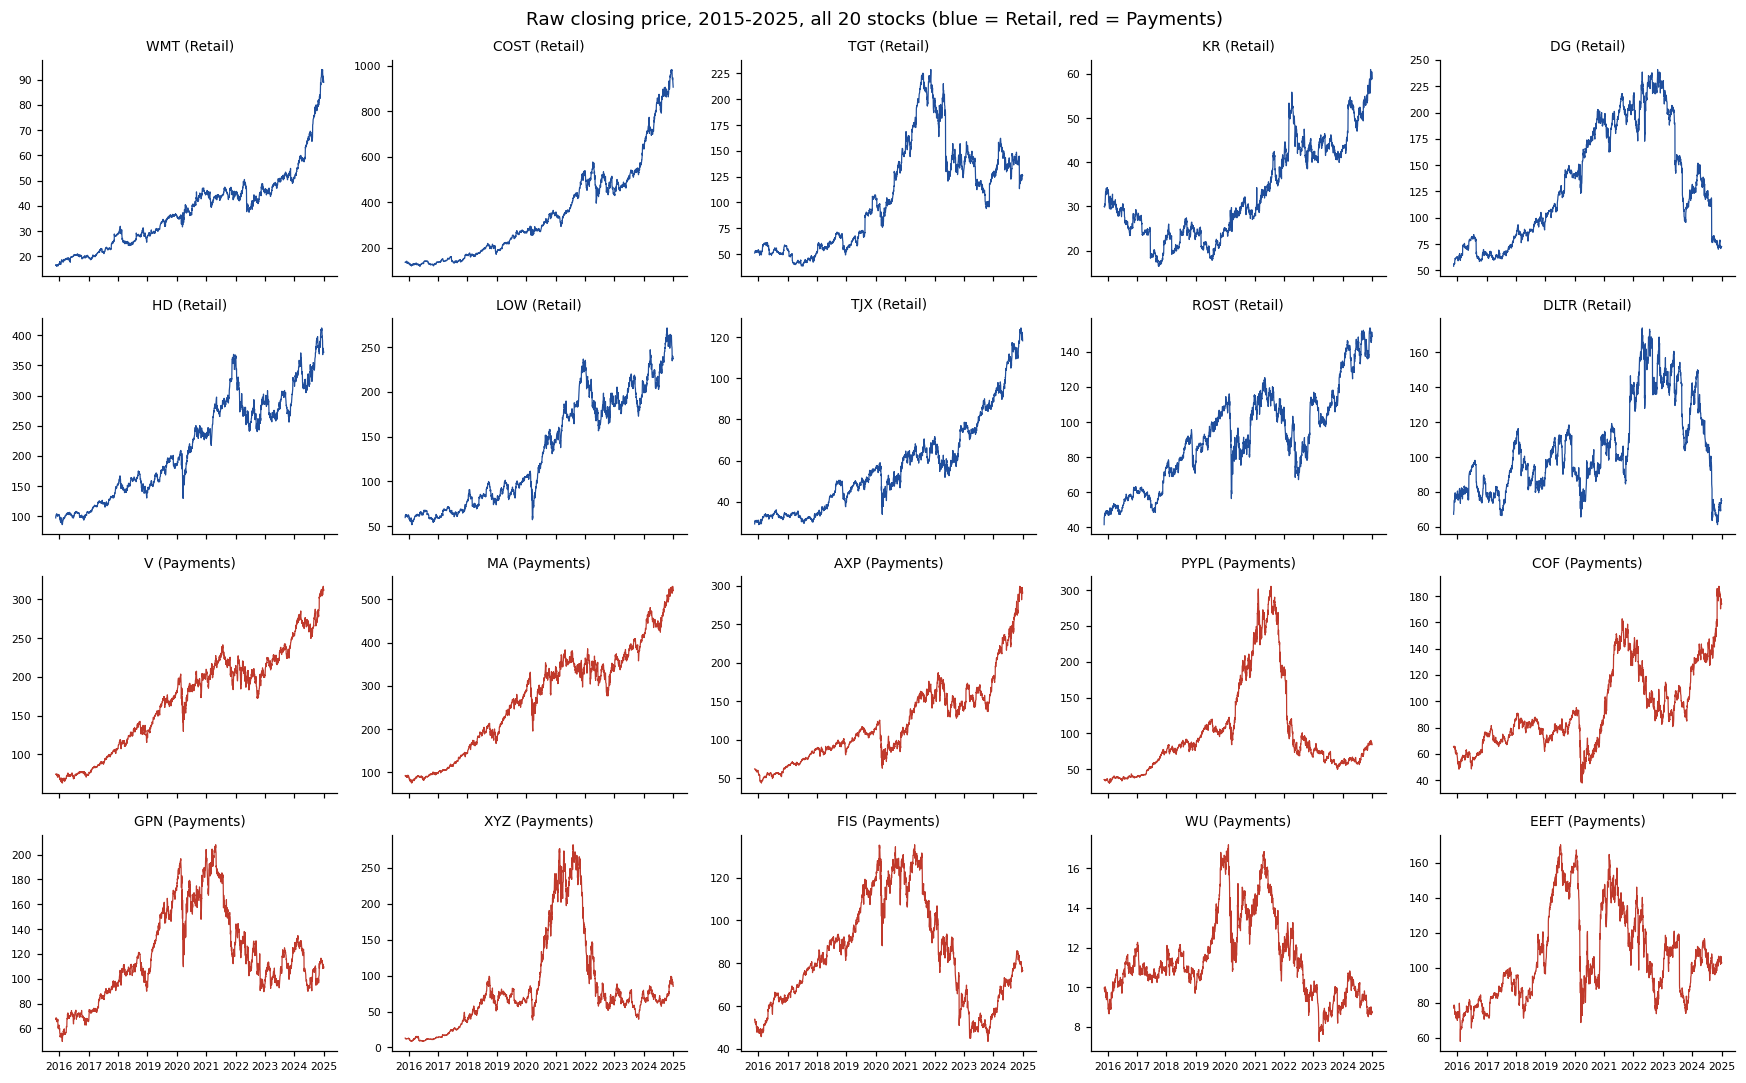

In [6]:
fig, axes = plt.subplots(4, 5, figsize=(16, 10), sharex=True)
axes = axes.flatten()

for i, ticker in enumerate(all_tickers):
    ax = axes[i]
    color = '#1f4e9c' if ticker_sector[ticker] == 'Retail' else '#c0392b'
    ax.plot(prices.index, prices[ticker], color=color, linewidth=0.8)
    ax.set_title(f"{ticker} ({ticker_sector[ticker]})", fontsize=9)
    ax.tick_params(labelsize=7)
    ax.spines[['top', 'right']].set_visible(False)

fig.suptitle('Raw closing price, 2015-2025, all 20 stocks (blue = Retail, red = Payments)', fontsize=12)
fig.tight_layout()
plt.show()

## 3. Do stocks within the same sector move together?

Raw prices are on very different scales (a $50 stock vs. a $400 stock), so we normalize each
stock to start at 100. This makes it easy to compare *shape* of the trend, not the dollar amount.

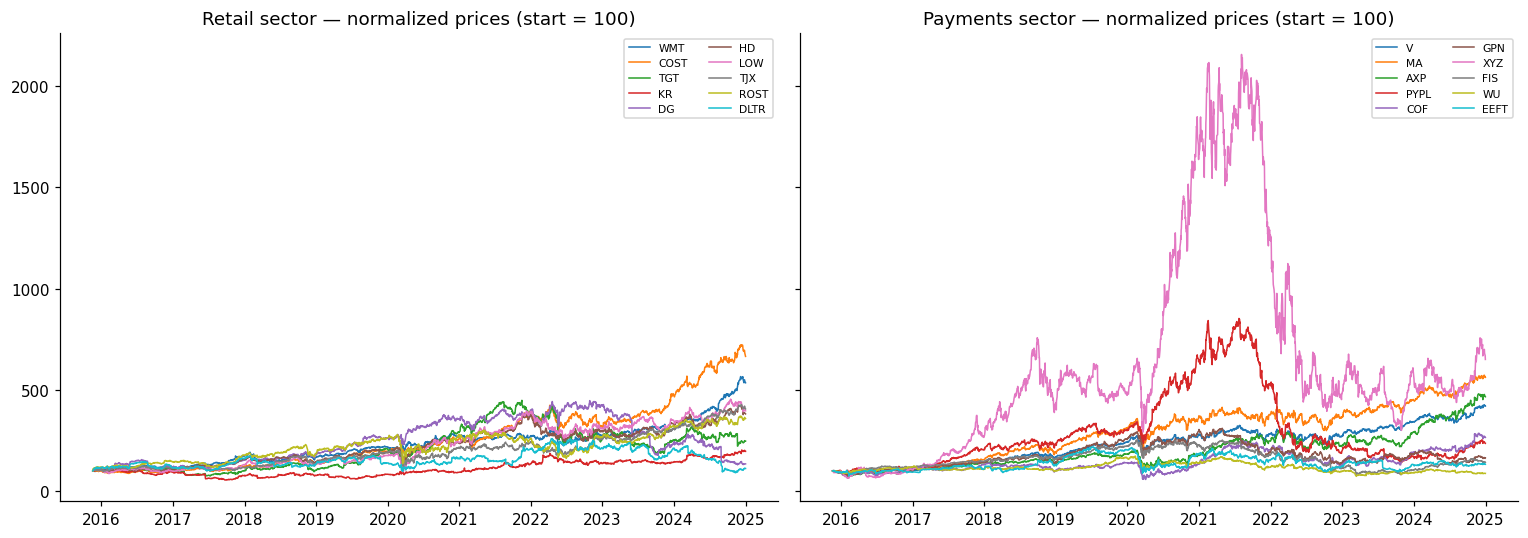

In [7]:
normalized = 100 * prices / prices.iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ticker in sectors['Retail']:
    axes[0].plot(normalized.index, normalized[ticker], label=ticker, linewidth=1)
axes[0].set_title('Retail sector — normalized prices (start = 100)')
axes[0].legend(fontsize=7, ncol=2)
axes[0].spines[['top', 'right']].set_visible(False)

for ticker in sectors['Payments']:
    axes[1].plot(normalized.index, normalized[ticker], label=ticker, linewidth=1)
axes[1].set_title('Payments sector — normalized prices (start = 100)')
axes[1].legend(fontsize=7, ncol=2)
axes[1].spines[['top', 'right']].set_visible(False)

fig.tight_layout()
plt.show()

## 4. Preview: the pair this project focuses on

Walmart (WMT) and Mastercard (MA) are the main pair we'll test formally in later notebooks.
Here's what they look like side by side, with no statistics yet — just a visual preview of
the question: do these two stocks really move together, or does it just look that way?

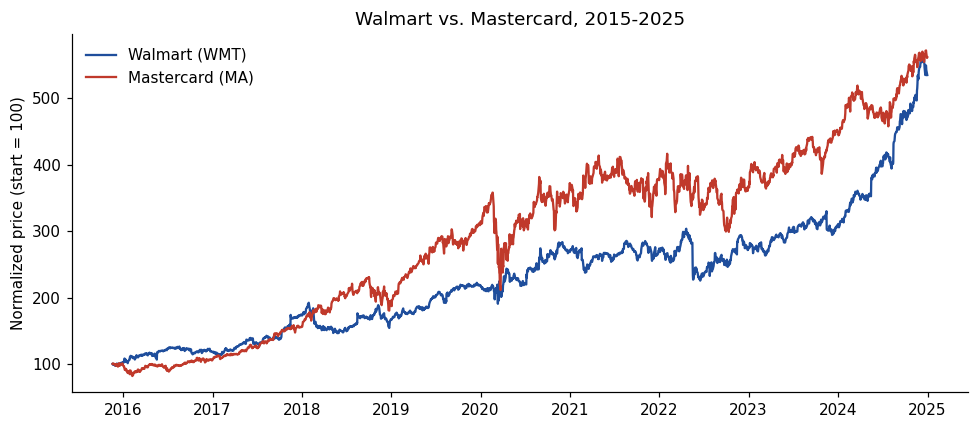

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(normalized.index, normalized['WMT'], label='Walmart (WMT)', color='#1f4e9c')
ax.plot(normalized.index, normalized['MA'], label='Mastercard (MA)', color='#c0392b')
ax.set_ylabel('Normalized price (start = 100)')
ax.set_title('Walmart vs. Mastercard, 2015-2025')
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

## 5. Where does COVID-19 show up in the data?

The March 2020 crash is a known external shock. We mark it directly on the chart, since later
notebooks will ask whether this one event distorts our statistical conclusions.

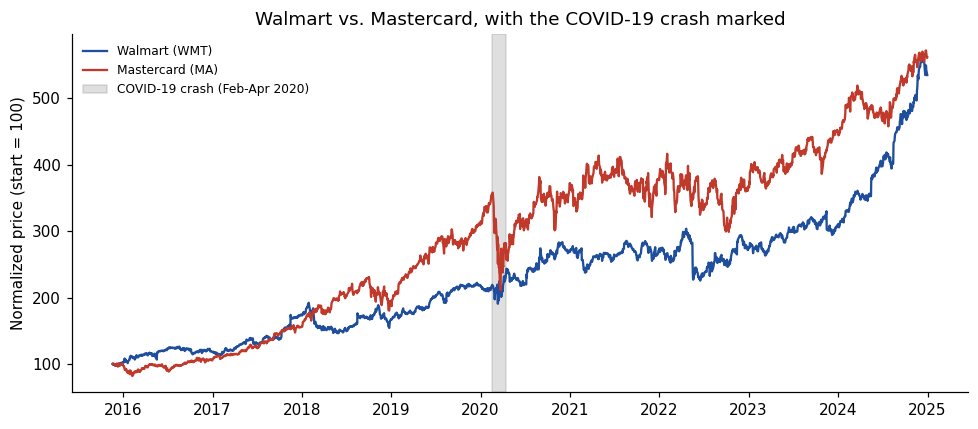

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(normalized.index, normalized['WMT'], label='Walmart (WMT)', color='#1f4e9c')
ax.plot(normalized.index, normalized['MA'], label='Mastercard (MA)', color='#c0392b')
ax.axvspan(pd.Timestamp('2020-02-15'), pd.Timestamp('2020-04-15'), color='gray', alpha=0.25,
           label='COVID-19 crash (Feb-Apr 2020)')
ax.set_ylabel('Normalized price (start = 100)')
ax.set_title('Walmart vs. Mastercard, with the COVID-19 crash marked')
ax.legend(frameon=False, fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

## 6. Are daily returns "well-behaved"?

Later notebooks need to assume things like independence and normality for some statistical
tests. Let's check, visually, whether that looks reasonable for a typical stock's daily returns.

We use WMT as the example here.

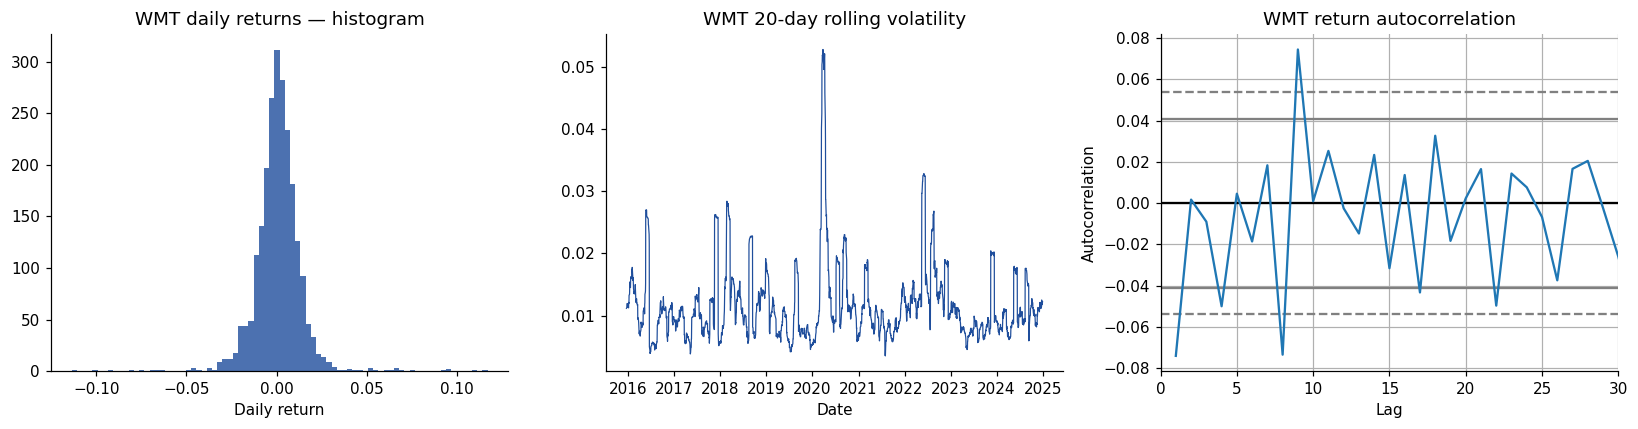

If the histogram has fatter tails than a normal bell curve, and volatility visibly
clusters (calm periods vs. turbulent periods) rather than staying flat, that's a sign
daily returns are not independent or normal — this motivates the fixes used later
(Newey-West standard errors, block bootstrap).


In [10]:
returns = prices.pct_change().dropna()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# (a) Histogram of daily returns — check for heavy tails / non-normality
axes[0].hist(returns['WMT'], bins=80, color='#1f4e9c', alpha=0.8)
axes[0].set_title('WMT daily returns — histogram')
axes[0].set_xlabel('Daily return')
axes[0].spines[['top', 'right']].set_visible(False)

# (b) Rolling volatility — check for volatility clustering
rolling_vol = returns['WMT'].rolling(20).std()
axes[1].plot(rolling_vol.index, rolling_vol.values, color='#1f4e9c', linewidth=0.8)
axes[1].set_title('WMT 20-day rolling volatility')
axes[1].set_xlabel('Date')
axes[1].spines[['top', 'right']].set_visible(False)

# (c) Autocorrelation of returns — check for independence (or lack of it)
from pandas.plotting import autocorrelation_plot
autocorrelation_plot(returns['WMT'], ax=axes[2])
axes[2].set_title('WMT return autocorrelation')
axes[2].set_xlim(0, 30)
axes[2].spines[['top', 'right']].set_visible(False)

fig.tight_layout()
plt.show()

print("If the histogram has fatter tails than a normal bell curve, and volatility visibly")
print("clusters (calm periods vs. turbulent periods) rather than staying flat, that's a sign")
print("daily returns are not independent or normal — this motivates the fixes used later")
print("(Newey-West standard errors, block bootstrap).")

## 7. Correlation heatmap — a simple (non-statistical) preview of "which pairs look related"

This is just the Pearson correlation of daily returns across all 190 possible pairs. It is
**not** the formal cointegration test we'll run in Notebook 2 — correlation only checks if two
stocks move the same direction on the same day, not whether their price *gap* stays stable
over time. We show it here purely as an easy-to-read visual starting point.

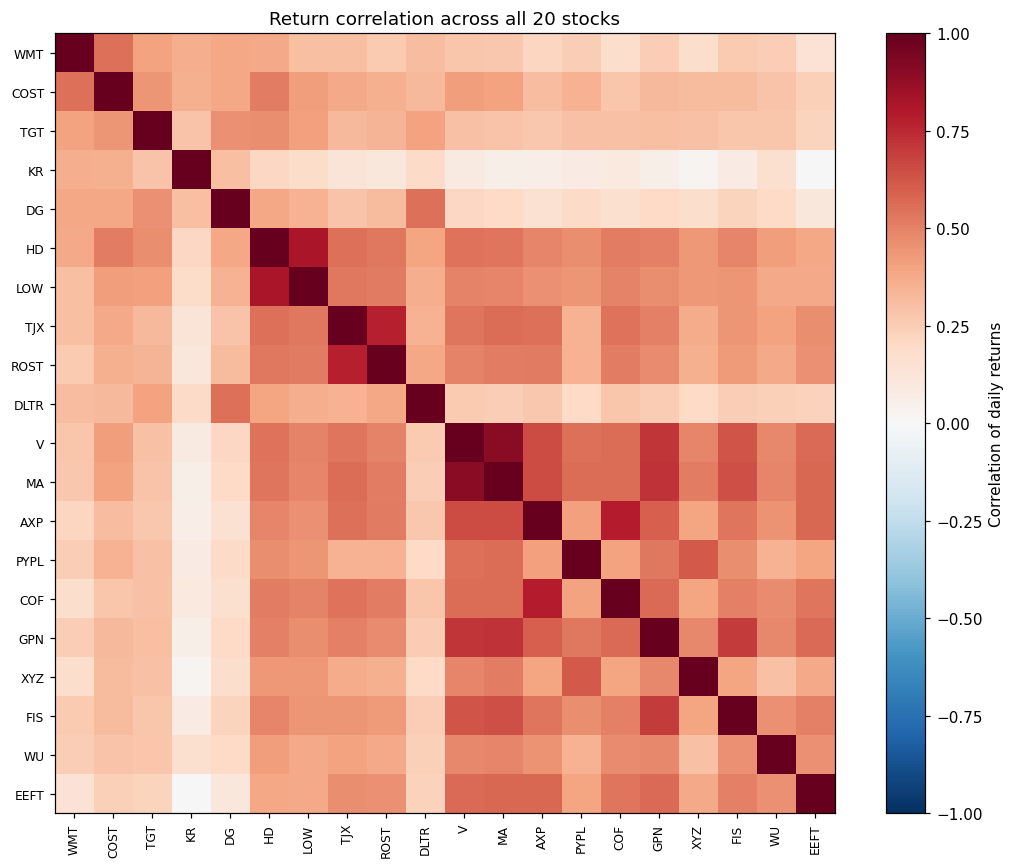

In [11]:
corr = returns[all_tickers].corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(all_tickers)))
ax.set_yticks(range(len(all_tickers)))
ax.set_xticklabels(all_tickers, rotation=90, fontsize=8)
ax.set_yticklabels(all_tickers, fontsize=8)
fig.colorbar(im, ax=ax, label='Correlation of daily returns')
ax.set_title('Return correlation across all 20 stocks')
fig.tight_layout()
plt.show()

## 8. Summary statistics table

A quick per-stock reference table: average daily return, daily volatility (standard
deviation), and annualized volatility, so later results have something to compare against.

In [12]:
summary = pd.DataFrame({
    'sector': [ticker_sector[t] for t in all_tickers],
    'mean_daily_return_%': (returns[all_tickers].mean() * 100).round(4),
    'daily_vol_%': (returns[all_tickers].std() * 100).round(3),
    'annualized_vol_%': (returns[all_tickers].std() * np.sqrt(252) * 100).round(1),
}, index=all_tickers)

summary.sort_values('sector')

,sector,mean_daily_return_%,daily_vol_%,annualized_vol_%
EEFT,Payments,0.0387,2.296,36.5
FIS,Payments,0.0329,1.843,29.3
XYZ,Payments,0.1478,3.625,57.5
GPN,Payments,0.0432,2.086,33.1
COF,Payments,0.0697,2.325,36.9
PYPL,Payments,0.0665,2.399,38.1
AXP,Payments,0.0868,1.992,31.6
MA,Payments,0.0900,1.713,27.2
V,Payments,0.0746,1.552,24.6
WU,Payments,0.0083,1.672,26.5


## 9. Save outputs to Google Drive

Save the full price history and daily returns to the `01_data_exploration` Drive subfolder,
so Notebook 2 can pull them directly from there without re-downloading anything.

In [13]:
prices.to_csv('prices_full.csv')
returns.to_csv('returns_full.csv')
summary.to_csv('summary_stats.csv')

for fname in ['prices_full.csv', 'returns_full.csv', 'summary_stats.csv']:
    upload_file(fname, this_folder_id)

print("Saved locally and uploaded to Drive: prices_full.csv, returns_full.csv, summary_stats.csv")

Uploaded prices_full.csv to Drive.
Uploaded returns_full.csv to Drive.
Uploaded summary_stats.csv to Drive.
Saved locally and uploaded to Drive: prices_full.csv, returns_full.csv, summary_stats.csv


## Next notebook

**Notebook 2** picks up from `prices_full.csv`, splits it into Train (2015-2023) and Verify
(2023-2025), runs the formal cointegration test on all 190 pairs (Train only), and compares
naive vs. Bonferroni vs. FDR correction — including how the independence issue in this
time-series data is handled.